# Eksperimen CODAMOSA vs CoverUp

Notebook ini menjalankan **generator CODAMOSA dan CoverUp**, kemudian mengevaluasi
test yang dihasilkan dengan evaluator bersama di `eval_metrics.py` untuk HumanEval
dan Refactory. Default notebook adalah **pilot satu task per dataset**. Ubah
`TASK_LIMIT=None` di `.env` setelah pilot berhasil untuk menjalankan semua task.

Credential hanya dibaca dari environment kernel dan tidak disimpan ke notebook.

### Kernel Python wajib

Pilih kernel **Python (.venv Teori Pengujian)** sebelum menjalankan cell. Kernel harus
menggunakan `./.venv/bin/python`, bukan `/usr/bin/python3`. Jika kernel belum muncul,
jalankan `./.venv/bin/python -m ipykernel install --user --name teori-pengujian
--display-name 'Python (.venv Teori Pengujian)'`, lalu pilih kernel tersebut.

Preflight mengirim satu request kecil ke provider, sehingga request tersebut dapat
dikenai biaya.

### Format model

Notebook ini dikonfigurasi untuk endpoint OpenAI-compatible OctaLabs
(`https://router.octalabs.id/v1`). Untuk CoverUp, `openai/` hanyalah prefix
transport LiteLLM; contoh `openai/claude-sonnet-5` dikirim sebagai
`claude-sonnet-5`. CODAMOSA mengirim bare model ID secara langsung.
Alias lama `entah/...` dinormalisasi otomatis. Setiap model dijalankan terpisah.

Jika salah satu metode gagal, notebook tidak mengarang skor. Status `BLOCKED` dan
diagnosis disimpan di `experiment_results/status.json`; metode lain tetap dicoba.


In [1]:
from pathlib import Path
import csv
import json
import os
import shutil
import subprocess
import sys
import time
import tempfile
import importlib.util
import hashlib

try:
    from dotenv import load_dotenv
except ImportError:
    def load_dotenv(dotenv_path, override=False):
        path = Path(dotenv_path)
        if not path.exists():
            return False
        for raw_line in path.read_text(encoding='utf-8').splitlines():
            line = raw_line.strip()
            if not line or line.startswith('#') or '=' not in line:
                continue
            key, value = line.split('=', 1)
            key, value = key.strip(), value.strip()
            if len(value) >= 2 and value[0] == value[-1] and value[0] in (chr(39), chr(34)):
                value = value[1:-1]
            if override or key not in os.environ:
                os.environ[key] = value
        return True

ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'eval_metrics.py').exists():
    raise FileNotFoundError(
        'Buka notebook dari root repositori yang berisi src/eval_metrics.py '
        'atau sesuaikan ROOT.'
    )
sys.path.insert(0, str(ROOT / 'src'))
import eval_metrics as em

# Fail early with the actual kernel interpreter instead of producing misleading
# per-task BLOCKED messages when VS Code selected a stale Linux .venv kernel.
REQUIRED_HOST_PACKAGES = (
    'litellm', 'requests', 'dotenv', 'nbclient', 'aiolimiter',
    'numpy', 'pandas', 'matplotlib',
)
missing_host_packages = [name for name in REQUIRED_HOST_PACKAGES if importlib.util.find_spec(name) is None]
if missing_host_packages:
    raise RuntimeError(
        'Dependency host tidak lengkap pada interpreter notebook ' + sys.executable
        + ': ' + ', '.join(missing_host_packages)
        + '. Pilih kernel Python (.venv Teori Pengujian) di VS Code; jika belum tersedia, '
        + 'jalankan .venv/bin/python -m ipykernel install --user --name teori-pengujian '
        + "--display-name 'Python (.venv Teori Pengujian)'."
    )
print('Notebook interpreter:', sys.executable)
print('Host dependencies: OK (' + ', '.join(REQUIRED_HOST_PACKAGES) + ')')

load_dotenv(ROOT / 'config' / '.env', override=True)
# OctaLabs is the actual provider. Populate compatibility names only in-memory
# because LiteLLM and the CodaMOSA CLI require these conventional names.
_octa_key = (os.getenv('OCTA_API_KEY') or os.getenv('OPENAI_API_KEY')
             or os.getenv('CODAMOSA_API_KEY') or '').strip()
if _octa_key:
    os.environ['OPENAI_API_KEY'] = _octa_key
    os.environ['CODAMOSA_API_KEY'] = _octa_key
if os.getenv('OPENAI_BASE_URL') and not os.getenv('OPENAI_API_BASE'):
    os.environ['OPENAI_API_BASE'] = os.environ['OPENAI_BASE_URL']
os.environ.setdefault('LITELLM_LOCAL_MODEL_COST_MAP', 'True')

DATASETS = ['HumanEval', 'Refactory']
_task_limit_raw = os.getenv('TASK_LIMIT', 'all').strip()
TASK_LIMIT = None if _task_limit_raw.lower() in {'', 'none', 'all', '0'} else int(_task_limit_raw)

def provider_model_id(model):
    model = model.strip()
    return model[len('entah/'):] if model.startswith('entah/') else model

def coverup_model_name(model):
    model = provider_model_id(model)
    return model if model.startswith('openai/') else 'openai/' + model

def codamosa_model_name(model):
    model = provider_model_id(model)
    return model[len('openai/'):] if model.startswith('openai/') else model

COVERUP_MODELS = [coverup_model_name(m) for m in os.getenv('COVERUP_MODELS', 'openai/claude-sonnet-5').split(',') if m.strip()]
COVERUP_TIMEOUT = int(os.getenv('COVERUP_TIMEOUT', '900'))
CODAMOSA_MODELS = [codamosa_model_name(m) for m in os.getenv('CODAMOSA_MODELS', 'claude-sonnet-5').split(',') if m.strip()]
assert COVERUP_MODELS and all(m.startswith('openai/') for m in COVERUP_MODELS), COVERUP_MODELS
assert CODAMOSA_MODELS and all(not m.startswith('openai/') for m in CODAMOSA_MODELS), CODAMOSA_MODELS
CODAMOSA_IMAGE = os.getenv('CODAMOSA_IMAGE', 'pynguin-runner:latest')
CODAMOSA_SEARCH_SECONDS = int(os.getenv('CODAMOSA_SEARCH_SECONDS', '60'))
CODAMOSA_POPULATION = int(os.getenv('CODAMOSA_POPULATION', '5'))

# Keep task-level and mutation-level parallelism within the available CPU budget.
TASK_WORKERS = max(1, int(os.getenv('TASK_WORKERS', '2')))
_cpu_budget = max(1, min(6, (os.cpu_count() or 6) // 2))
_requested_mutant_workers = max(1, int(os.getenv('EVAL_MUTANT_WORKERS', '3')))
EVAL_MUTANT_WORKERS = min(
    _requested_mutant_workers,
    max(1, _cpu_budget // TASK_WORKERS),
)
os.environ['EVAL_MUTANT_WORKERS'] = str(EVAL_MUTANT_WORKERS)
CODAMOSA_DOCKER_CPUS = max(1.0, float(os.getenv('CODAMOSA_DOCKER_CPUS', '2')))
GENERATOR_ATTEMPTS = max(1, int(os.getenv('GENERATOR_ATTEMPTS', '3')))
GENERATOR_RETRY_SECONDS = max(0.0, float(os.getenv('GENERATOR_RETRY_SECONDS', '3')))
print('Parallel task workers:', TASK_WORKERS)
print('Effective mutation workers:', EVAL_MUTANT_WORKERS)

OUT = ROOT / 'experiment_results'
OUT.mkdir(parents=True, exist_ok=True)
import experiment_storage as _storage
store = _storage.ResultStore(OUT)
store.begin(os.getenv('RUN_LABEL', 'manual'))
print('Run candidate dir:', store.candidate)
if os.getenv('FRESH', '0').strip().lower() in {'1', 'true', 'yes'}:
    print('FRESH requested; active results are still retained and will be backed up on promote.')
TASKS = {name: em.task_ids(name, TASK_LIMIT) for name in DATASETS}
_task_filter_raw = os.getenv('TASK_FILTER', '').strip()
if _task_filter_raw:
    _wanted = set()
    for _piece in _task_filter_raw.replace(';', ',').split(','):
        _piece = _piece.strip()
        if not _piece:
            continue
        if ':' in _piece:
            _ds, _tid = _piece.split(':', 1)
            _wanted.add((_ds.strip(), _tid.strip()))
        else:
            _wanted.add((None, _piece))
    TASKS = {ds: [t for t in tids if (ds, str(t)) in _wanted or (None, str(t)) in _wanted]
             for ds, tids in TASKS.items()}
    TASKS = {ds: tids for ds, tids in TASKS.items() if tids}
    print('TASK_FILTER:', _task_filter_raw, '->', TASKS)
RESUME = os.getenv('RESUME', '0').strip().lower() in {'1', 'true', 'yes'}

print('Root:', ROOT)
print('Tasks:', TASKS)
print('CoverUp models:', COVERUP_MODELS)
print('CODAMOSA models configured:', CODAMOSA_MODELS)
print('OPENAI_BASE_URL:', os.getenv('OPENAI_BASE_URL'))
print('LITELLM_LOCAL_MODEL_COST_MAP:', os.getenv('LITELLM_LOCAL_MODEL_COST_MAP'))


Notebook interpreter: /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main/.venv/bin/python
Host dependencies: OK (litellm, requests, dotenv, nbclient, aiolimiter, numpy, pandas, matplotlib)
Parallel task workers: 1
Effective mutation workers: 1
Run candidate dir: /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main/experiment_results/runs/20261010T164023Z_manual
Root: /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main
Tasks: {'HumanEval': ['0', '1', '2', '3', '4'], 'Refactory': ['q1', 'q2', 'q3', 'q4', 'q5']}
CoverUp models: ['openai/claude-sonnet-5', 'openai/gpt-5.5']
CODAMOSA models configured: ['claude-sonnet-5', 'gpt-5.5']
OPENAI_BASE_URL: https://router.octalabs.id/v1
LITELLM_LOCAL_MODEL_COST_MAP: True


## Preflight

Preflight memisahkan masalah credential, model, endpoint, dependency, dan Docker.
API key tidak pernah dicetak. Error provider disaring dari key yang diketahui.


In [2]:
def redact(value):
    text = str(value)
    for secret in (os.getenv("OCTA_API_KEY"), os.getenv("OPENAI_API_KEY"), os.getenv("CODAMOSA_API_KEY")):
        if secret:
            text = text.replace(secret, "[REDACTED_API_KEY]")
    return text[:2500]


def explain_error(exc):
    detail = redact(f"{type(exc).__name__}: {exc}")
    lower = detail.lower()
    if "insufficient_quota" in lower or "credit_balance" in lower:
        action = "Key dikenali tetapi saldo/kredit habis. Periksa billing/kuota provider."
    elif "401" in lower or "unauthorized" in lower or "invalid api key" in lower:
        action = "Credential ditolak. Periksa key, project/provider, dan environment kernel."
    elif "403" in lower or "forbidden" in lower:
        action = "Credential tidak memiliki izin untuk model atau endpoint tersebut."
    elif "404" in lower or "not found" in lower or "model_not_found" in lower:
        action = "Model/route tidak ditemukan. Periksa nama model dan URL endpoint."
    elif "429" in lower or "rate limit" in lower:
        action = "Rate limit tercapai. Kurangi request/paralelisme atau tunggu cooldown."
    elif "405" in lower or "method not allowed" in lower:
        action = "Endpoint tidak menerima method/payload ini. Pastikan path chat-completions benar."
    elif ("timeout" in lower or "connection" in lower or "network" in lower
          or "name resolution" in lower or "failed to resolve" in lower):
        action = "Endpoint tidak terjangkau/timeout. Periksa jaringan, DNS Docker, URL, dan TLS."
    elif "upstream service" in lower or "service unavailable" in lower:
        action = "Provider upstream gagal sementara. Notebook akan retry; jika berulang, tunggu cooldown atau gunakan model lain."
    else:
        action = "Periksa detail provider, model, endpoint, credential, dan dependency."
    return detail + "\nLangkah berikutnya: " + action


def coverup_preflight():
    """One cheap call per model; OK only when every model returns a completion."""
    if not (os.getenv("OCTA_API_KEY") or os.getenv("OPENAI_API_KEY")):
        return False, "BLOCKED: OCTA_API_KEY tidak ditemukan di environment kernel.", None
    if not COVERUP_MODELS:
        return False, "BLOCKED: COVERUP_MODELS kosong.", None
    try:
        import litellm
    except ImportError as exc:
        return False, "BLOCKED: paket litellm tidak tersedia.\n" + explain_error(exc), None
    errors, ok_models = [], []
    for model in COVERUP_MODELS:
        try:
            result = litellm.completion(
                model=model,
                messages=[{"role": "user", "content": "Reply with OK."}],
                max_tokens=1,
                timeout=45,
            )
            if getattr(result, "choices", None):
                ok_models.append(model)
            else:
                errors.append(f"{model}: provider merespons tanpa completion choices.")
        except Exception as exc:
            errors.append(f"{model}: " + explain_error(exc))
    if errors:
        return False, "BLOCKED: preflight CoverUp gagal untuk salah satu model.\n" + "\n---\n".join(errors), None
    return True, f"OK: {len(ok_models)}/{len(COVERUP_MODELS)} model CoverUp menghasilkan completion valid.", ok_models[0]


def codamosa_preflight():
    base = os.getenv("CODAMOSA_BASE_URL", "https://router.octalabs.id/v1").strip().rstrip("/")
    path = os.getenv("CODAMOSA_COMPLETIONS_PATH", "/chat/completions").strip()
    default_style = "chat" if "chat/completions" in path else "legacy"
    style = os.getenv("CODAMOSA_API_STYLE", default_style).strip().lower()
    key = os.getenv("OCTA_API_KEY") or os.getenv("CODAMOSA_API_KEY") or os.getenv("OPENAI_API_KEY")
    if not CODAMOSA_MODELS:
        return False, "BLOCKED: CODAMOSA_MODELS kosong.", None
    if not key:
        return False, "BLOCKED: CODAMOSA_API_KEY atau OPENAI_API_KEY tidak ditemukan di environment kernel.", None
    try:
        import requests
    except ImportError as exc:
        return False, "BLOCKED: paket requests tidak tersedia.\n" + explain_error(exc), None
    errors, ok_models = [], []
    for model in CODAMOSA_MODELS:
        try:
            if base == "https://api.openai.com" and style != "chat":
                url = base + "/v1/engines/" + model + "/completions"
                payload = {"prompt": "Reply OK.", "max_tokens": 1, "temperature": 0}
            elif style == "chat":
                url = base + "/" + path.lstrip("/")
                payload = {"model": model, "messages": [{"role": "user", "content": "Reply OK."}], "max_tokens": 1, "temperature": 0}
            else:
                url = base + "/" + path.lstrip("/")
                payload = {"model": model, "prompt": "Reply OK.", "max_tokens": 1, "temperature": 0}
            _preflight_timeout = max(1, int(os.getenv("CODAMOSA_PREFLIGHT_TIMEOUT", "90")))
            response = requests.post(url, json=payload, headers={"Authorization": "Bearer " + key, "Content-Type": "application/json"}, timeout=(15, _preflight_timeout))
            response.raise_for_status()
            body = response.json()
            choice = (body.get("choices") or [{}])[0]
            if style == "chat":
                valid = (choice.get("message") or {}).get("content") is not None
            else:
                valid = "text" in choice
            if not valid:
                errors.append(f"{model}: response tidak sesuai mode {style}.")
                continue
            ok_models.append(model)
        except Exception as exc:
            errors.append(f"{model}: " + explain_error(exc))
    if errors:
        return False, "BLOCKED: preflight CODAMOSA gagal untuk salah satu model.\n" + "\n---\n".join(errors), None
    return True, f"OK: {len(ok_models)}/{len(CODAMOSA_MODELS)} model CODAMOSA menghasilkan completion valid ({style}).", ok_models[0]


def docker_preflight():
    if not shutil.which("docker"):
        return False, "BLOCKED: Docker CLI tidak ditemukan. Install Docker Engine/CLI."
    try:
        result = subprocess.run(
            ["docker", "info", "--format", "{{.ServerVersion}}"],
            capture_output=True,
            text=True, encoding="utf-8", errors="replace",
            timeout=20,
        )
        if result.returncode:
            return False, (
                "BLOCKED: Docker daemon tidak dapat diakses: "
                + redact((result.stderr or "") + (result.stdout or ""))
                + ". Start daemon dan pastikan user memiliki izin Docker."
            )
        image = subprocess.run(
            ["docker", "image", "inspect", CODAMOSA_IMAGE], capture_output=True,
            text=True, encoding="utf-8", errors="replace", timeout=20,
        )
        if image.returncode:
            return True, "OK: Docker daemon aktif; DNS container diperiksa setelah image dibangun."
        host = os.getenv("CODAMOSA_BASE_URL", "https://router.octalabs.id/v1").split("//", 1)[-1].split("/", 1)[0].split(":", 1)[0]
        dns = subprocess.run(
            ["docker", "run", "--rm", "--entrypoint", "python", CODAMOSA_IMAGE,
             "-c", "import socket,sys; socket.getaddrinfo(sys.argv[1], 443); print('DNS OK')", host],
            capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=30,
        )
        if dns.returncode:
            return False, (
                "BLOCKED: container CODAMOSA tidak dapat resolve endpoint " + host + ": "
                + redact((dns.stderr or "") + (dns.stdout or ""))
                + ". Perbaiki DNS Docker lalu ulangi preflight."
            )
        return True, "OK: Docker daemon aktif (" + (result.stdout or "").strip() + ") dan DNS container berfungsi."
    except Exception as exc:
        return False, "BLOCKED: pemeriksaan Docker/DNS gagal.\n" + explain_error(exc)


coverup_ok, coverup_reason, ACTIVE_COVERUP_MODEL = coverup_preflight()
codamosa_ok, codamosa_reason, ACTIVE_CODAMOSA_MODEL = codamosa_preflight()
docker_ok, docker_reason = docker_preflight()
if codamosa_ok and not docker_ok:
    codamosa_ok = False
    codamosa_reason += "\n" + docker_reason

print("CoverUp:", coverup_reason)
print("CODAMOSA:", codamosa_reason)
print("Docker:", docker_reason)
if coverup_ok:
    print("CoverUp active model:", ACTIVE_COVERUP_MODEL)
if codamosa_ok:
    print("CODAMOSA active model:", ACTIVE_CODAMOSA_MODEL)



CoverUp: OK: 2/2 model CoverUp menghasilkan completion valid.
CODAMOSA: OK: 2/2 model CODAMOSA menghasilkan completion valid (chat).
Docker: OK: Docker daemon aktif (29.1.3) dan DNS container berfungsi.
CoverUp active model: openai/claude-sonnet-5
CODAMOSA active model: claude-sonnet-5


In [3]:
def _codamosa_source_sha():
    digest = hashlib.sha256()
    for candidate in sorted((ROOT / "codamosa").rglob("*")):
        if candidate.is_file() and candidate.name != ".DS_Store" and "__pycache__" not in candidate.parts:
            digest.update(str(candidate.relative_to(ROOT / "codamosa")).encode("utf-8"))
            digest.update(candidate.read_bytes())
    return digest.hexdigest()


def ensure_codamosa_image():
    source_sha = _codamosa_source_sha()
    check = subprocess.run(
        ["docker", "image", "inspect", CODAMOSA_IMAGE,
         "--format", "{{index .Config.Labels \"org.codamosa.source-sha\"}}"],
        capture_output=True,
        text=True, encoding="utf-8", errors="replace",
    )
    if check.returncode == 0 and (check.stdout or "").strip() == source_sha:
        return True, "Menggunakan image yang sinkron dengan source: " + CODAMOSA_IMAGE
    if check.returncode == 0:
        print("Image CODAMOSA stale/unlabeled; rebuilding from current source.")
    command = [
        "docker", "build", "--build-arg", "CODAMOSA_SOURCE_SHA=" + source_sha,
        "-t", CODAMOSA_IMAGE,
        "-f", str(ROOT / "codamosa" / "docker" / "Dockerfile"),
        str(ROOT / "codamosa"),
    ]
    try:
        result = subprocess.run(
            command, capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=1800
        )
        if result.returncode:
            return False, (
                "BLOCKED: build image CODAMOSA gagal (exit "
                + str(result.returncode) + ").\n"
                + redact(((result.stdout or "") + "\n" + (result.stderr or ""))[-5000:])
                + "\nPeriksa koneksi registry, ruang disk, dan Dockerfile."
            )
        return True, "OK: image CODAMOSA berhasil dibangun."
    except Exception as exc:
        return False, "BLOCKED: build image CODAMOSA gagal.\n" + explain_error(exc)


if codamosa_ok:
    image_ok, image_reason = ensure_codamosa_image()
    print(image_reason)
    if not image_ok:
        codamosa_ok = False
        codamosa_reason += "\n" + image_reason
else:
    image_reason = "Dilewati karena preflight CODAMOSA gagal."


Menggunakan image yang sinkron dengan source: pynguin-runner:latest


## Menjalankan generator dan evaluasi

Test yang berhasil saja masuk ke `rows.csv`. Bila generator gagal, task dicatat
sebagai `BLOCKED` dengan alasan dan saran perbaikan di `status.json`.


In [4]:
rows = []
statuses = []
RESUME_KEYS = set()
if RESUME:
    _active_rows, _active_statuses = _storage.ResultStore._read_active(OUT)
    _selected = {(ds, str(t)) for ds, tids in TASKS.items() for t in tids}
    rows = [r for r in _active_rows if (r.get('dataset'), str(r.get('task'))) in _selected]
    statuses = [x for x in _active_statuses
                if x.get('status') == 'OK'
                and (x.get('dataset'), str(x.get('task'))) in _selected]
    for _item in statuses:
        if _item.get('status') == 'OK':
            RESUME_KEYS.add((_item.get('method'), _item.get('model'),
                             _item.get('dataset'), str(_item.get('task'))))
    print(f'RESUME=1: loaded {len(rows)} rows and {len(statuses)} statuses.')


def blocked(method, dataset, task, reason):
    item = {
        "method": method,
        "dataset": dataset,
        "task": str(task),
        "status": "BLOCKED",
        "message": redact(reason),
    }
    statuses.append(item)
    print("\n[" + method + " | " + dataset + " " + str(task) + "] BLOCKED")
    print(item["message"])


def validate_generated_suite(method, layout, tests, work):
    validation_work = work / "validation"
    if validation_work.exists():
        shutil.rmtree(validation_work)
    validation_work.mkdir(parents=True)
    try:
        invalid = []
        assertion_total = 0
        for test_file in tests:
            valid, reason, assertions = em.suite_validity(Path(test_file))
            if not valid:
                invalid.append(Path(test_file).name + " (" + reason + ")")
            assertion_total += assertions
        if invalid:
            raise RuntimeError("INVALID_GENERATED_TEST: " + "; ".join(invalid))
        prepared = em.prepare_suite(layout, tests, validation_work)
        if assertion_total <= 0:
            raise RuntimeError("INVALID_GENERATED_TEST: no assertions can be evaluated")
        collect_env = dict(os.environ, PYTHONPATH=str(validation_work), NO_COLOR="1", PYTEST_DISABLE_PLUGIN_AUTOLOAD="1")
        collect_cmd = [
            em.PY, em.PYTEST, "--collect-only", "-q", "-p", "no:cacheprovider",
            "--no-header", "-o", "addopts=", *[p.name for p in prepared["pytest_files"]]
        ]
        collect = subprocess.run(
            collect_cmd, cwd=str(validation_work), env=collect_env,
            capture_output=True, text=True, encoding="utf-8", errors="replace", timeout=120,
        )
        (work / "pytest_collect.stdout.log").write_text(collect.stdout or "", encoding="utf-8")
        (work / "pytest_collect.stderr.log").write_text(collect.stderr or "", encoding="utf-8")
        if collect.returncode != 0 or not prepared["units"]:
            raise RuntimeError(
                "Suite " + method + " gagal import/pytest collection sebelum evaluasi. Inspect "
                + str(work / "pytest_collect.stderr.log")
                + "\n"
                + redact(((collect.stdout or "") + "\n" + (collect.stderr or ""))[-3000:])
            )
        return prepared
    finally:
        shutil.rmtree(validation_work, ignore_errors=True)


def _model_slug(model):
    return model.replace("/", "_")


def _run_coverup_task_with_model(dataset, task, model):
    layout = em.LAYOUTS[dataset](str(task))
    work = OUT / "work" / "coverup" / _model_slug(model) / dataset / str(task)
    result = em.run_coverup(
        Path(layout["put"]), work / "tests", work,
        model=model, timeout=COVERUP_TIMEOUT,
    )
    if result is None or not result.ok:
        raise RuntimeError(
            (result.error if result else "CoverUp tidak dijalankan")
            or "CoverUp exited non-zero; inspect " + str(work / "coverup.log")
        )
    if not result.generated_tests:
        raise RuntimeError(
            "CoverUp selesai tetapi tidak menghasilkan test_coverup_*.py; inspect "
            + str(work / "coverup.log")
        )
    generated = [Path(p) for p in result.generated_tests]
    validate_generated_suite("CoverUp", layout, generated, work)
    row = em.evaluate(
        dataset, str(task), generated, "CoverUp",
        wall_time_s=result.wall_time_s, cost_usd=result.cost_usd,
        workroot=OUT / "work",
    )
    row["generator_ok"] = True
    row["model"] = model
    return row


def _run_codamosa_task_with_model(dataset, task, model):
    layout = em.LAYOUTS[dataset](str(task))
    source = Path(layout["put"]).resolve()
    module = source.stem
    work = OUT / "work" / "codamosa" / _model_slug(model) / dataset / str(task)
    project = work / "project"
    output = work / "output"
    if work.exists():
        shutil.rmtree(work)
    project.mkdir(parents=True)
    output.mkdir(parents=True)
    shutil.copy2(source, project / source.name)
    (project / "package.txt").write_text("")

    base = os.getenv("CODAMOSA_BASE_URL", "https://router.octalabs.id/v1").strip().rstrip("/")
    relative = os.getenv("CODAMOSA_COMPLETIONS_PATH", "/chat/completions").strip()
    key = os.getenv("OCTA_API_KEY") or os.getenv("CODAMOSA_API_KEY") or os.getenv("OPENAI_API_KEY", "")
    args = [
        "--assertion-generation", "MUTATION_ANALYSIS",
        "--project_path", "/input",
        "--module-name", module,
        "--output-path", "/output",
        "--maximum_search_time", str(CODAMOSA_SEARCH_SECONDS),
        "--algorithm", "CODAMOSA",
        "--model_name", model,
        "--model_base_url", base,
        "--model_relative_url", relative,
        "--temperature", "0.8",
        "--large_language_model_seeding", "True",
        "--uninterpreted_statements", "ONLY",
        "--include-partially-parsable", "True",
        "--allow-expandable-cluster", "True",
        "--seeded_testcases_reuse_probability", "1",
        "--population", str(CODAMOSA_POPULATION),
    ]
    auth_file = None
    try:
        with tempfile.NamedTemporaryFile(
            mode="w", prefix="codamosa-auth-", encoding="utf-8", delete=False
        ) as handle:
            auth_file = Path(handle.name)
            handle.write("--authorization-key\n" + key + "\n")
        auth_file.chmod(0o600)
        command = [
            "docker", "run", "--rm",
            "--cpus", str(CODAMOSA_DOCKER_CPUS),
            "-v", str(project) + ":/input:ro",
            "-v", str(output) + ":/output",
            "-v", str(project) + ":/package:ro",
            "-v", str(auth_file) + ":/run/codamosa-auth:ro",
            CODAMOSA_IMAGE,
            "@/run/codamosa-auth",
        ] + args
        started = time.perf_counter()
        try:
            result = subprocess.run(
                command,
                capture_output=True,
                text=True,
                encoding="utf-8",
                errors="replace",
                timeout=CODAMOSA_SEARCH_SECONDS + 600,
            )
        except subprocess.TimeoutExpired as exc:
            raise RuntimeError(
                "CODAMOSA container timeout.\n"
                + redact((exc.stdout or "") + (exc.stderr or ""))
            ) from exc
    finally:
        if auth_file is not None:
            auth_file.unlink(missing_ok=True)
    elapsed = time.perf_counter() - started
    (work / "docker.stdout.log").write_text(result.stdout or "", encoding="utf-8")
    (work / "docker.stderr.log").write_text(result.stderr or "", encoding="utf-8")
    if result.returncode:
        raise RuntimeError(
            "CODAMOSA/Docker exit code " + str(result.returncode) + ":\n"
            + redact(((result.stdout or "") + "\n" + (result.stderr or ""))[-5000:])
        )
    generated = []
    invalid = []
    primary = [p for p in sorted(output.rglob("test_script_*.py"))
               if not p.name.endswith("_failing.py")
               and not p.name.endswith("_failing_no_metadata.py")]
    for candidate in primary:
        valid, reason, _assertions = em.suite_validity(candidate)
        if valid:
            generated.append(candidate)
        else:
            invalid.append(candidate.name + " (" + reason + ")")
    diagnostic = sorted(output.rglob("*_failing.py"))
    if not generated:
        detail = "INVALID_GENERATED_TEST: suite utama CODAMOSA kosong/tidak valid."
        if invalid:
            detail += " Artefak utama: " + ", ".join(invalid)
        if diagnostic:
            detail += " *_failing.py hanya diagnostik dan tidak dinilai sebagai sukses: "
            detail += ", ".join(p.name for p in diagnostic)
        detail += ". Inspect " + str(work / "docker.stdout.log")
        raise RuntimeError(detail)

    validate_generated_suite("CODAMOSA", layout, generated, work)

    row = em.evaluate(
        dataset, str(task), generated, "CODAMOSA",
        wall_time_s=elapsed, workroot=OUT / "work",
    )

    row["generator_ok"] = True
    row["model"] = model
    return row


# Matrix: method x model x dataset x task. Each model has isolated outputs.
# Workers use isolated work directories and return data. Only the notebook's
# main thread mutates rows/statuses and writes checkpoints.
def _done(method, model, dataset, task):
    return (method, model, dataset, str(task)) in RESUME_KEYS


_TRANSIENT_ERROR_MARKERS = (
    "429", "rate limit", "too many requests", "502", "503", "504",
    "bad gateway", "service unavailable", "upstream service",
    "connectionerror", "connection reset", "connection refused",
    "connection aborted", "network is unreachable", "temporary failure",
    "name resolution", "failed to resolve", "could not resolve", "dns",
    "timed out", "timeout", "docker daemon", "cannot connect to the docker",
    "no such host", "eof",
)


def _retryable_failure(exc, method):
    """Return whether an exception is safe to retry at the task boundary.

    Generated-suite validity is deterministic evidence, not a transient provider
    failure.  A transient HTTP/transport marker anywhere in the message is
    retryable -- including one preserved inside a CoverUp log excerpt, where the
    helper otherwise only sees "tidak menghasilkan test".  CoverUp's exhausted
    generation and no-coverage-progress outcomes carry no such marker, so they
    fail fast instead of repeating a deterministic run that costs another call.
    """
    text = str(exc).lower()
    if "invalid_generated_test" in text:
        return False
    return any(marker in text for marker in _TRANSIENT_ERROR_MARKERS)


def _run_with_retries(method, model, dataset, task, runner):
    last_exc = None
    for attempt in range(1, GENERATOR_ATTEMPTS + 1):
        try:
            return runner()
        except Exception as exc:  # noqa: BLE001 - per-task isolation boundary
            last_exc = exc
            retry = attempt < GENERATOR_ATTEMPTS and _retryable_failure(exc, method)
            if not retry:
                raise
            print(f"{method} {model} {dataset} {task}: attempt {attempt} transient failure; retry.")
            if GENERATOR_RETRY_SECONDS:
                time.sleep(GENERATOR_RETRY_SECONDS * attempt)
    raise last_exc  # pragma: no cover - loop always returns or raises above


def _blocked_record(method, dataset, task, reason):
    _reason = redact(reason)
    _status = "INVALID_GENERATED_TEST" if "INVALID_GENERATED_TEST" in _reason else "BLOCKED"
    _method, _sep, _model = method.partition(":")
    item = {"method": _method, "model": _model if _sep else None,
            "dataset": dataset, "task": str(task),
            "status": _status, "message": _reason}
    print("\n[" + method + " | " + dataset + " " + str(task) + "] " + _status)
    print(item["message"])
    return item


def _run_one_task(dataset, task):
    task_rows, task_statuses = [], []
    if coverup_ok:
        for model in COVERUP_MODELS:
            if _done("CoverUp", model, dataset, task):
                print(f"RESUME skip CoverUp {model} {dataset} {task}")
                continue
            try:
                print("CoverUp mencoba model:", model, "|", dataset, task)
                row = _run_with_retries(
                    "CoverUp", model, dataset, task,
                    lambda: _run_coverup_task_with_model(dataset, task, model),
                )
                task_rows.append(row)
                task_statuses.append({"method": "CoverUp", "model": model,
                    "dataset": dataset, "task": str(task), "status": "OK",
                    "message": "Generation and evaluation completed."})
                print("CoverUp OK", model, dataset, task)
            except Exception as exc:
                task_statuses.append(_blocked_record(
                    "CoverUp:" + model, dataset, task, explain_error(exc)))
    else:
        for model in COVERUP_MODELS:
            if not _done("CoverUp", model, dataset, task):
                task_statuses.append(_blocked_record(
                    "CoverUp:" + model, dataset, task, coverup_reason))

    if codamosa_ok:
        for model in CODAMOSA_MODELS:
            if _done("CODAMOSA", model, dataset, task):
                print(f"RESUME skip CODAMOSA {model} {dataset} {task}")
                continue
            try:
                print("CODAMOSA mencoba model:", model, "|", dataset, task)
                row = _run_with_retries(
                    "CODAMOSA", model, dataset, task,
                    lambda: _run_codamosa_task_with_model(dataset, task, model),
                )
                task_rows.append(row)
                task_statuses.append({"method": "CODAMOSA", "model": model,
                    "dataset": dataset, "task": str(task), "status": "OK",
                    "message": "Generation and evaluation completed."})
                print("CODAMOSA OK", model, dataset, task)
            except Exception as exc:
                task_statuses.append(_blocked_record(
                    "CODAMOSA:" + model, dataset, task, explain_error(exc)))
    else:
        for model in CODAMOSA_MODELS:
            if not _done("CODAMOSA", model, dataset, task):
                task_statuses.append(_blocked_record(
                    "CODAMOSA:" + model, dataset, task, codamosa_reason))
    return task_rows, task_statuses


from concurrent.futures import ThreadPoolExecutor, as_completed

_task_jobs = [(dataset, str(task))
              for dataset, task_ids in TASKS.items()
              for task in task_ids]
if _task_jobs:
    _worker_count = min(TASK_WORKERS, len(_task_jobs))
    print(f"Starting {_worker_count} parallel task workers for {len(_task_jobs)} tasks.")
    with ThreadPoolExecutor(max_workers=_worker_count,
                            thread_name_prefix="experiment-task") as _executor:
        _future_to_task = {
            _executor.submit(_run_one_task, dataset, task): (dataset, task)
            for dataset, task in _task_jobs
        }
        for _future in as_completed(_future_to_task):
            dataset, task = _future_to_task[_future]
            try:
                _task_rows, _task_statuses = _future.result()
            except Exception as exc:
                _task_rows, _task_statuses = [], []
                _reason = "Unexpected task worker error: " + explain_error(exc)
                for model in COVERUP_MODELS:
                    if not _done("CoverUp", model, dataset, task):
                        _task_statuses.append(_blocked_record(
                            "CoverUp:" + model, dataset, task, _reason))
                for model in CODAMOSA_MODELS:
                    if not _done("CODAMOSA", model, dataset, task):
                        _task_statuses.append(_blocked_record(
                            "CODAMOSA:" + model, dataset, task, _reason))
            rows.extend(_task_rows)
            statuses.extend(_task_statuses)
            store.checkpoint(rows, statuses)
            print(f"Checkpoint after {dataset} {task}: rows={len(rows)} statuses={len(statuses)}")
else:
    print("No tasks selected; nothing to run.")


Starting 1 parallel task workers for 10 tasks.
CoverUp mencoba model: openai/claude-sonnet-5 | HumanEval 0


CoverUp openai/claude-sonnet-5 HumanEval 0: attempt 1 transient failure; retry.


CoverUp openai/claude-sonnet-5 HumanEval 0: attempt 2 transient failure; retry.



[CoverUp:openai/claude-sonnet-5 | HumanEval 0] BLOCKED
RuntimeError: CoverUp tidak menghasilkan test setelah generator berhenti. Log run terbaru:
": {
              "type": "string",
              "description": "class, function or method name, as in 'f' for function f or 'C.foo' for method foo in class C."
            }
          },
          "required": [
            "name"
          ]
        }
      }
    }
  ]
}
---- 2026-10-10T23:41:32 script_0.py:4-19 ----
{
  "id": "msg_1c720f82813d4ea096035d973b4b22a1",
  "created": 1791650475,
  "model": "claude-sonnet-5",
  "object": "chat.completion",
  "system_fingerprint": null,
  "choices": [
    {
      "finish_reason": "stop",
      "index": 0,
      "message": {
        "content": "```python\nimport pytest\nfrom typing import List\n\ndef has_close_elements(numbers: List[float], threshold: float) -> bool:\n    \"\"\" Check if in given list of numbers, are any two numbers closer to each other than\n    given threshold.\n    >>> has_clo

CoverUp OK openai/gpt-5.5 HumanEval 0
CODAMOSA mencoba model: claude-sonnet-5 | HumanEval 0


...


[CODAMOSA:gpt-5.5 | Refactory q4] BLOCKED
RuntimeError: CODAMOSA/Docker exit code 1:
                     │
│    95 │   """                                                                │
│    96 │   try:                                                               │
│    97 │   │   _LOGGER.info("Start Pynguin Test Generation…")                 │
│ ❱  98 │   │   return _run()                                                  │
│    99 │   finally:                                                           │
│   100 │   │   _LOGGER.info("Stop Pynguin Test Generation…")                  │
│   101                                                                        │
│                                                                              │
│ /usr/local/lib/python3.10/site-packages/pynguin/generator.py:385 in _run     │
│                                                                              │
│   382 │   │   executor, test_cluster                                         │


CoverUp OK openai/claude-sonnet-5 Refactory q5
CoverUp mencoba model: openai/gpt-5.5 | Refactory q5


CoverUp OK openai/gpt-5.5 Refactory q5
CODAMOSA mencoba model: claude-sonnet-5 | Refactory q5



[CODAMOSA:claude-sonnet-5 | Refactory q5] INVALID_GENERATED_TEST
RuntimeError: INVALID_GENERATED_TEST: suite utama CODAMOSA kosong/tidak valid. Artefak utama: test_script_q5.py (no test functions (empty/comment-only suite)) *_failing.py hanya diagnostik dan tidak dinilai sebagai sukses: test_script_q5_failing.py. Inspect /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main/experiment_results/work/codamosa/claude-sonnet-5/Refactory/q5/docker.stdout.log
Langkah berikutnya: Periksa detail provider, model, endpoint, credential, dan dependency.
CODAMOSA mencoba model: gpt-5.5 | Refactory q5



[CODAMOSA:gpt-5.5 | Refactory q5] INVALID_GENERATED_TEST
RuntimeError: INVALID_GENERATED_TEST: suite utama CODAMOSA kosong/tidak valid. Artefak utama: test_script_q5.py (no test functions (empty/comment-only suite)) *_failing.py hanya diagnostik dan tidak dinilai sebagai sukses: test_script_q5_failing.py. Inspect /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main/experiment_results/work/codamosa/gpt-5.5/Refactory/q5/docker.stdout.log
Langkah berikutnya: Periksa detail provider, model, endpoint, credential, dan dependency.
Checkpoint after Refactory q5: rows=25 statuses=40


## Simpan hasil

`rows.csv` hanya berisi task yang selesai digenerate dan dievaluasi. `status.json`
berisi status semua task, termasuk alasan metode yang belum dapat berjalan.


In [5]:
if _task_filter_raw:
    _selected = {(ds, str(t)) for ds, tids in TASKS.items() for t in tids}
    _ar, _ast = _storage.ResultStore._read_active(OUT)
    rows = [r for r in _ar if (r.get('dataset'), str(r.get('task'))) not in _selected] + rows
    statuses = [x for x in _ast if (x.get('dataset'), str(x.get('task'))) not in _selected] + statuses
    print(f'TASK_FILTER merge: {len(rows)} rows and {len(statuses)} statuses after merge.')
expected_statuses = sum(len(task_ids) for task_ids in TASKS.values()) * (len(COVERUP_MODELS) + len(CODAMOSA_MODELS))
if _task_filter_raw:
    expected_statuses = len(statuses)
manifest = store.finalize(rows, statuses, expected_statuses=expected_statuses)
print("Run manifest:", json.dumps(manifest, indent=2, ensure_ascii=False))
if not manifest["promoted"]:
    print("Active results preserved; inspect candidate:", store.candidate)

print("Rows:", OUT / "rows.csv")
print("Statuses:", OUT / "status.json")
print("OK:", sum(item["status"] == "OK" for item in statuses))
print("BLOCKED:", sum(item["status"] == "BLOCKED" for item in statuses))
print("INVALID_GENERATED_TEST:", sum(item["status"] == "INVALID_GENERATED_TEST" for item in statuses))

print("\nResult summary:")
print("OK:", sum(item["status"] == "OK" for item in statuses))
print("BLOCKED:", sum(item["status"] == "BLOCKED" for item in statuses))
print("INVALID_GENERATED_TEST:", sum(item["status"] == "INVALID_GENERATED_TEST" for item in statuses))
if rows:
    summary_groups = {}
    for row in rows:
        key = (row.get("dataset"), row.get("method"), row.get("model"))
        summary_groups.setdefault(key, []).append(row)
    for (dataset, method, model), group in sorted(summary_groups.items()):
        def avg(field):
            vals = [float(r[field]) for r in group if r.get(field) not in (None, "")]
            return round(sum(vals) / len(vals), 2) if vals else None
        print(
            f"{dataset} | {method} | {model}: "
            f"tasks={len(group)}, "
            f"coverage={avg('line_pct')}, "
            f"pass_rate={avg('pass_rate')}, "
            f"mutation_score={avg('mutation_score')}, "
            f"wall_time_s={avg('wall_time_s')}, "
            f"cost_usd={avg('cost_usd')}"
        )
else:
    print("No successful rows; inspect status.json for blocked methods/tasks.")



Run manifest: {
  "run_id": "20261010T164023Z_manual",
  "valid": true,
  "promoted": false,
  "backup": null,
  "expected_statuses": 40,
  "actual_statuses": 40,
  "old_quality": [
    30,
    66.444444444,
    30
  ],
  "new_quality": [
    25,
    66.545454545,
    25
  ],
  "mutant_set_conflicts": {}
}
Active results preserved; inspect candidate: /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main/experiment_results/runs/20261010T164023Z_manual
Rows: /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main/experiment_results/rows.csv
Statuses: /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main/experiment_results/status.json
OK: 25
BLOCKED: 9
INVALID_GENERATED_TEST: 6

Result summary:
OK: 25
BLOCKED: 9
INVALID_GENERATED_TEST: 6
HumanEval | CODAMOSA | claude-sonnet-5: tasks=3, coverage=100.0, pass_rate=100.0, mutation_score=0.0, wall_time_s=16.56, cost_usd=None
HumanEval | CODAMOSA | gpt-5.5: tasks=3, coverage=96.97, pass_rate=100.0, mutation_score=0.0, wall_time_s=11.53, cos

## Visualisasi perbandingan dan analisis akurasi

Cell berikut membaca **hanya hasil run saat ini yang berstatus OK**, lalu membuat gambar `experiment_results/comparison.png`. Label menampilkan metode dan model sebenarnya. Prefix `openai/` pada CoverUp adalah transport LiteLLM, bukan model berbeda.

Interpretasi berfokus pada **mutation score** sebagai ukuran kualitas utama. Coverage/pass rate yang tinggi belum berarti test akurat apabila mutant tetap hidup. Analisis alasan bersifat evidence-based: jumlah assertion, mutant survived/broken/timeout, validitas suite, dan karakter prompt/task.


### Ringkasan per dataset x metode x model

,dataset,method,model,tasks,mutation_score%,line_cov%,pass_rate%,gen_time_s,assertions,killed,survived,broken,timeout,cost_usd,mutant_set_total
0,HumanEval,CODAMOSA,claude-sonnet-5,3,0.0,100.00,100.0,16.56,6.67,0.0,4.00,0.0,0.0,NaN,6.0
1,HumanEval,CODAMOSA,gpt-5.5,3,0.0,96.97,100.0,11.53,2.33,0.0,5.67,0.0,0.0,NaN,8.0
2,HumanEval,CoverUp,claude-sonnet-5,4,0.0,100.00,100.0,15.22,6.75,0.0,4.50,0.0,0.0,0.00,8.0
3,HumanEval,CoverUp,gpt-5.5,5,0.0,100.00,100.0,9.77,2.40,0.0,4.80,0.0,0.0,0.01,8.0
4,Refactory,CODAMOSA,gpt-5.5,1,0.0,100.00,100.0,10.71,6.00,0.0,288.00,0.0,0.0,NaN,288.0
5,Refactory,CoverUp,claude-sonnet-5,4,0.0,100.00,100.0,17.96,8.25,0.0,351.50,0.0,0.0,0.00,575.0
6,Refactory,CoverUp,gpt-5.5,5,0.0,100.00,100.0,13.21,4.60,0.0,342.00,0.0,0.0,0.02,575.0


- **Pemeriksaan kesetaraan lolos**: setiap task memakai satu `mutant_set_id` yang sama untuk semua metode/model.

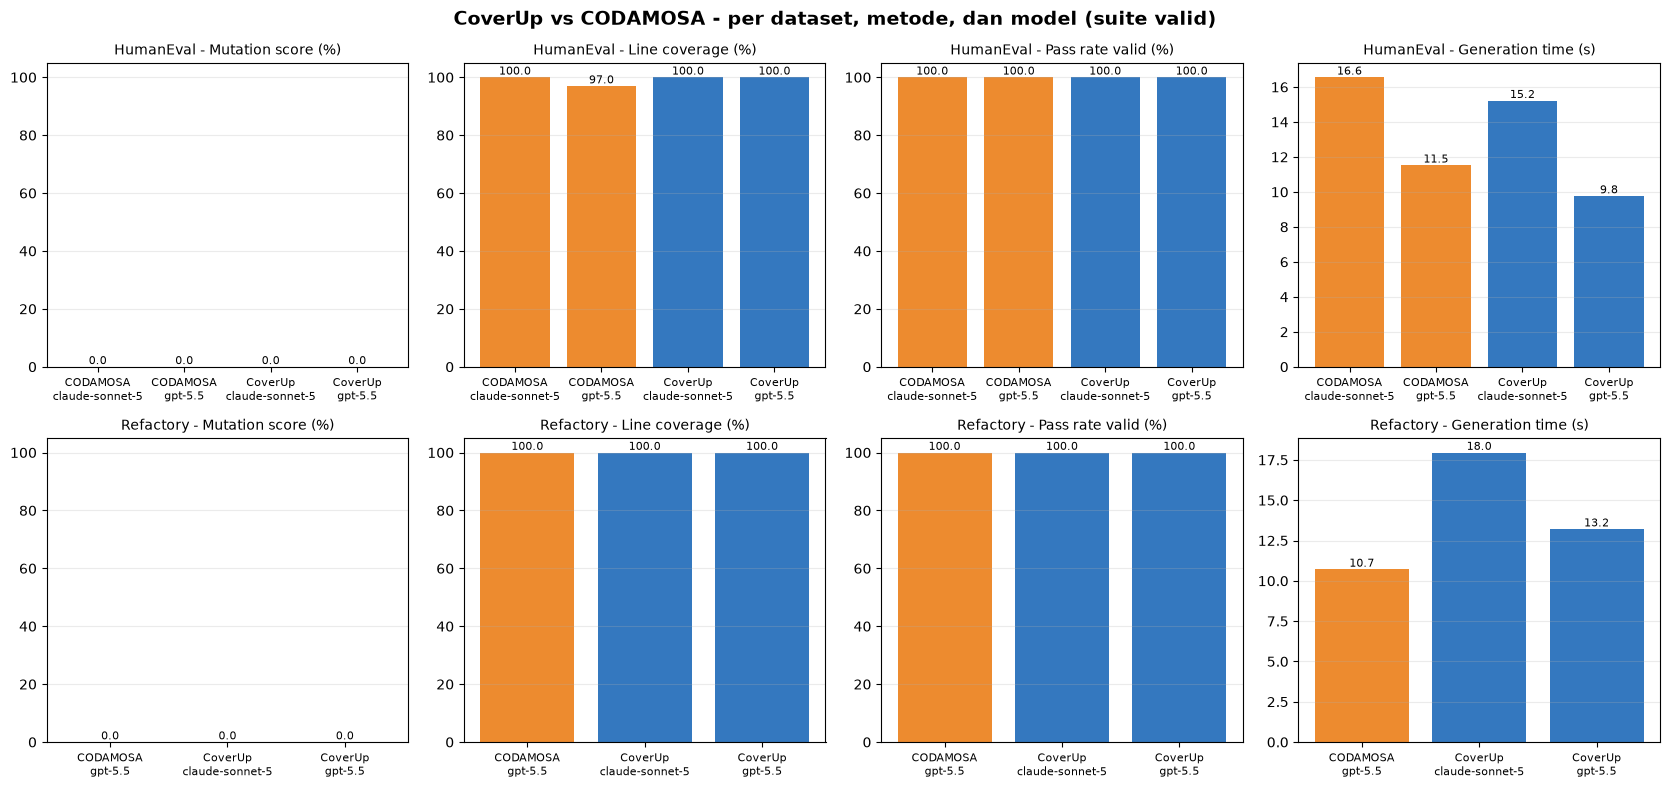

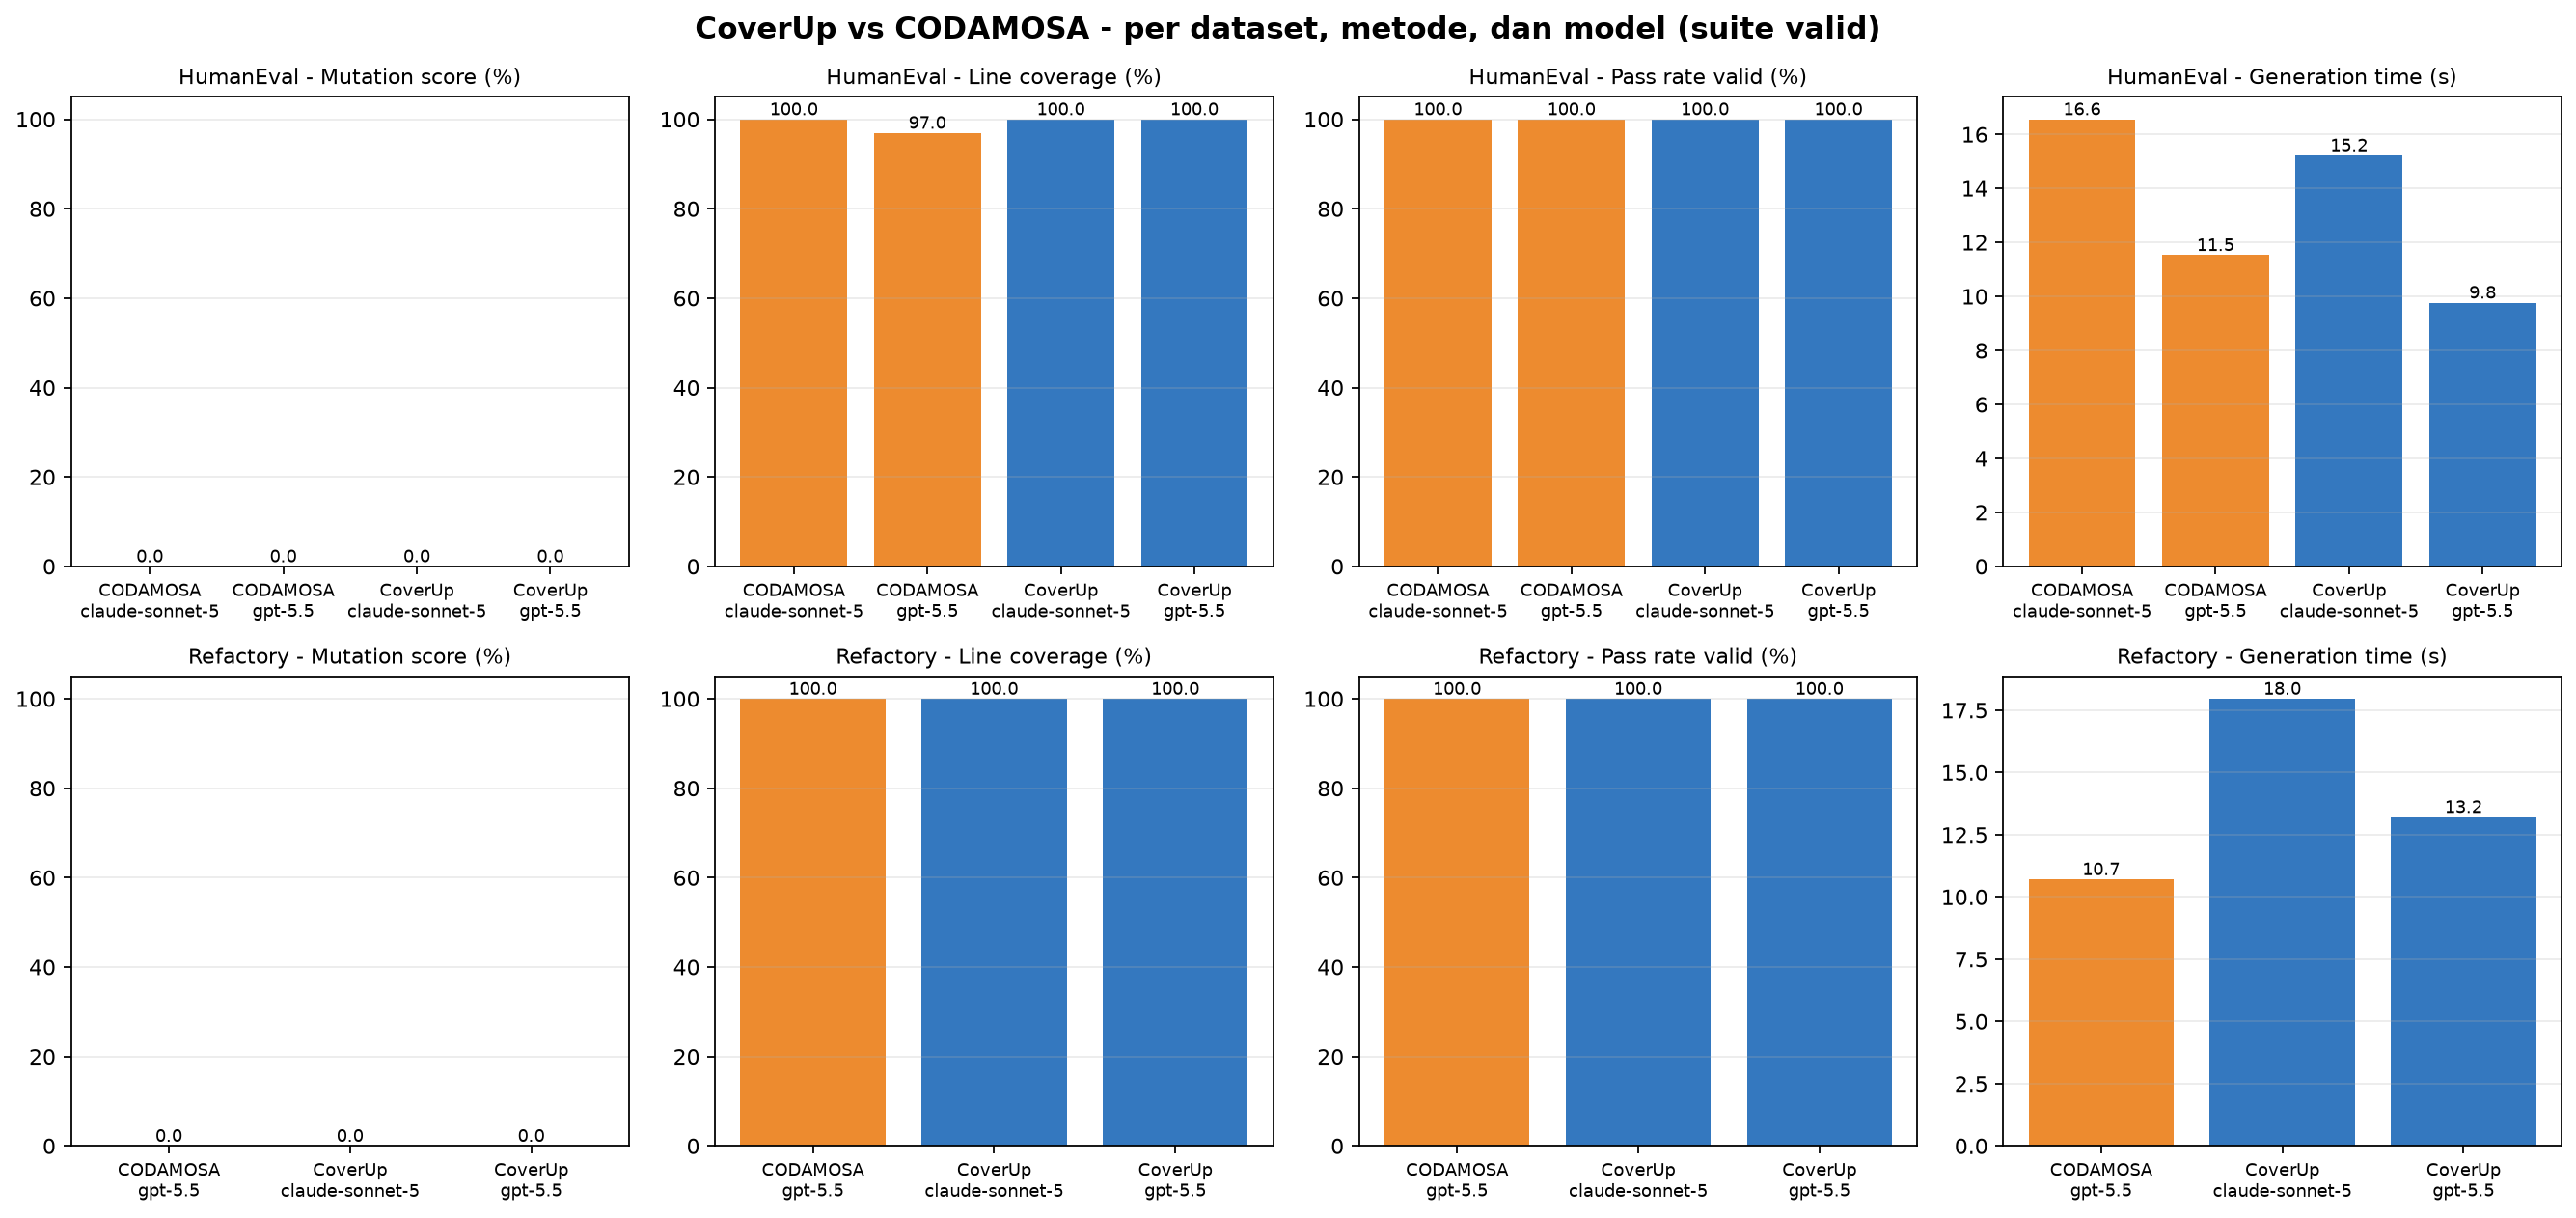

Chart disimpan di /home/masoyi/Teori-dalam-pengujian-perangkat-lunak-main/experiment_results/comparison.png


### Mengapa akurasi dapat rendah pada prompt/task tertentu?
- **CODAMOSA / claude-sonnet-5**, prompt `HumanEval:0`: mutation score 0.0% (0 killed, 6 survived, 0 broken, 0 timeout; 10 assertion). Test lebih banyak mengonfirmasi contoh normal/coverage daripada membedakan implementasi benar dari mutant; oracle dan edge case pada prompt ini kurang kuat.
- **CODAMOSA / gpt-5.5**, prompt `HumanEval:1`: mutation score 0.0% (0 killed, 8 survived, 0 broken, 0 timeout; 2 assertion). Test lebih banyak mengonfirmasi contoh normal/coverage daripada membedakan implementasi benar dari mutant; oracle dan edge case pada prompt ini kurang kuat.
- **CoverUp / claude-sonnet-5**, prompt `HumanEval:1`: mutation score 0.0% (0 killed, 8 survived, 0 broken, 0 timeout; 8 assertion). Test lebih banyak mengonfirmasi contoh normal/coverage daripada membedakan implementasi benar dari mutant; oracle dan edge case pada prompt ini kurang kuat.
- **CoverUp / gpt-5.5**, prompt `HumanEval:0`: mutation score 0.0% (0 killed, 6 survived, 0 broken, 0 timeout; 3 assertion). Test lebih banyak mengonfirmasi contoh normal/coverage daripada membedakan implementasi benar dari mutant; oracle dan edge case pada prompt ini kurang kuat.
- **CODAMOSA / gpt-5.5**, prompt `Refactory:q3`: mutation score 0.0% (0 killed, 288 survived, 0 broken, 0 timeout; 6 assertion). Test lebih banyak mengonfirmasi contoh normal/coverage daripada membedakan implementasi benar dari mutant; oracle dan edge case pada prompt ini kurang kuat.
- **CoverUp / claude-sonnet-5**, prompt `Refactory:q1`: mutation score 0.0% (0 killed, 575 survived, 0 broken, 0 timeout; 8 assertion). Test lebih banyak mengonfirmasi contoh normal/coverage daripada membedakan implementasi benar dari mutant; oracle dan edge case pada prompt ini kurang kuat.
- **CoverUp / gpt-5.5**, prompt `Refactory:q1`: mutation score 0.0% (0 killed, 575 survived, 0 broken, 0 timeout; 4 assertion). Test lebih banyak mengonfirmasi contoh normal/coverage daripada membedakan implementasi benar dari mutant; oracle dan edge case pada prompt ini kurang kuat.
- **15 suite/status tidak diskor** (misalnya suite kosong atau `except BaseException: pass`), sehingga pass rate tidak tampak bagus secara palsu.
- Kesimpulan sebab dibatasi pada artefak yang terukur; perbedaan skor tidak boleh dianggap semata-mata kelemahan model karena metode pencarian, prompt, waktu, dan task juga memengaruhi hasil.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ok_keys = {(x.get("method"), x.get("model"), x.get("dataset"), str(x.get("task")))
           for x in statuses if x.get("status") == "OK"}
valid_rows = [r for r in rows
              if (r.get("method"), r.get("model"), r.get("dataset"), str(r.get("task"))) in ok_keys]
invalid_rows = [x for x in statuses if x.get("status") != "OK"]


def _float(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return float("nan")


def _int(value):
    return 0 if np.isnan(value) else int(value)


def _model_name(model):
    return str(model or "-").removeprefix("openai/")


if not valid_rows:
    display(Markdown("**Belum ada hasil valid untuk divisualisasikan.** Periksa `status.json`; "
                     "suite kosong atau yang menelan exception sengaja tidak diberi skor."))
else:
    metric_fields = ["mutation_score", "line_pct", "pass_rate", "wall_time_s",
                     "n_assertions_evaluated", "killed", "survived", "broken",
                     "timeout", "mutant_set_total", "cost_usd"]
    records = []
    for row in valid_rows:
        record = {"dataset": row.get("dataset"), "method": row.get("method"),
                  "model": _model_name(row.get("model")), "task": str(row.get("task")),
                  "mutant_set_id": row.get("mutant_set_id")}
        for field in metric_fields:
            record[field] = _float(row.get(field))
        records.append(record)
    frame = pd.DataFrame(records)
    keys = ["dataset", "method", "model"]

    agg = {field: "mean" for field in metric_fields if field != "mutant_set_total"}
    agg["mutant_set_total"] = "max"
    summary = frame.groupby(keys, dropna=False).agg(agg).reset_index()
    summary.insert(3, "tasks", frame.groupby(keys, dropna=False).size().values)
    display(Markdown("### Ringkasan per dataset x metode x model"))
    display(summary.rename(columns={
        "mutation_score": "mutation_score%", "line_pct": "line_cov%",
        "pass_rate": "pass_rate%", "wall_time_s": "gen_time_s",
        "n_assertions_evaluated": "assertions"}).round(2))

    conflicts = []
    for (dataset, task), group in frame.groupby(["dataset", "task"], dropna=False):
        ids = {i for i in group["mutant_set_id"] if isinstance(i, str) and i}
        if len(ids) > 1:
            conflicts.append(f"{dataset}:{task} -> {sorted(ids)}")
    if conflicts:
        display(Markdown("- **Peringatan perbandingan tidak setara**: task berikut memakai "
                         "mutant_set_id berbeda, sehingga mutation score tidak dapat "
                         "dibandingkan langsung: " + "; ".join(conflicts)))
    elif frame["mutant_set_id"].isna().all():
        display(Markdown("- **Kesetaraan mutant set belum dapat diverifikasi**: baris berasal "
                         "dari run lama tanpa `mutant_set_id`."))
    else:
        display(Markdown("- **Pemeriksaan kesetaraan lolos**: setiap task memakai satu "
                         "`mutant_set_id` yang sama untuk semua metode/model."))


    chart_metrics = [
        ("mutation_score", "Mutation score (%)", True),
        ("line_pct", "Line coverage (%)", True),
        ("pass_rate", "Pass rate valid (%)", True),
        ("wall_time_s", "Generation time (s)", False),
    ]
    datasets = list(dict.fromkeys(frame["dataset"].astype(str)))
    fig, axes = plt.subplots(len(datasets), len(chart_metrics),
                             figsize=(4.2 * len(chart_metrics), 4 * len(datasets)),
                             squeeze=False)
    for row_index, dataset in enumerate(datasets):
        group = frame[frame["dataset"].astype(str) == dataset]
        for column_index, (field, title, fixed_scale) in enumerate(chart_metrics):
            ax = axes[row_index][column_index]
            series = group.groupby(["method", "model"], dropna=False)[field].mean()
            labels = [f"{method}\n{model}" for method, model in series.index]
            values = [0.0 if np.isnan(value) else value for value in series.values]
            colors = ["#3478bf" if method == "CoverUp" else "#ed8b2f"
                      for method, _model in series.index]
            bars = ax.bar(labels, values, color=colors)
            ax.set_title(f"{dataset} - {title}", fontsize=10)
            ax.grid(axis="y", alpha=.25)
            ax.tick_params(axis="x", labelsize=8)
            if fixed_scale:
                ax.set_ylim(0, 105)
            for bar, value in zip(bars, values):
                ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
                        f"{value:.1f}", ha="center", va="bottom", fontsize=8)
    fig.suptitle("CoverUp vs CODAMOSA - per dataset, metode, dan model (suite valid)",
                 fontsize=14, fontweight="bold")
    fig.tight_layout()
    chart_path = OUT / "comparison.png"
    fig.savefig(chart_path, dpi=160, bbox_inches="tight")
    plt.show()
    display(Image(filename=str(chart_path)))
    print("Chart disimpan di", chart_path)

    lines = ["### Mengapa akurasi dapat rendah pada prompt/task tertentu?"]
    for (dataset, method, model), group in frame.groupby(keys, dropna=False):
        worst = group.sort_values("mutation_score", na_position="first").iloc[0]
        score = worst["mutation_score"]
        survived, killed = _int(worst["survived"]), _int(worst["killed"])
        broken, timed_out = _int(worst["broken"]), _int(worst["timeout"])
        assertions = worst["n_assertions_evaluated"]
        assertions_text = "tidak tercatat" if np.isnan(assertions) else str(int(assertions))
        lines.append(
            f"- **{method} / {model}**, prompt `{dataset}:{worst['task']}`: mutation score "
            f"{0.0 if np.isnan(score) else score:.1f}% "
            f"({killed} killed, {survived} survived, {broken} broken, {timed_out} timeout; "
            f"{assertions_text} assertion).")
        if assertions_text == "tidak tercatat":
            lines[-1] += (" Baris ini berasal dari run lama tanpa penghitungan assertion; "
                          "jalankan ulang pilot agar buktinya lengkap.")
        elif survived and killed == 0:
            lines[-1] += (" Test lebih banyak mengonfirmasi contoh normal/coverage daripada "
                          "membedakan implementasi benar dari mutant; oracle dan edge case pada "
                          "prompt ini kurang kuat.")
        elif survived:
            lines[-1] += (" Sebagian mutant masih lolos, menunjukkan batas kondisi atau oracle "
                          "hasil belum lengkap.")
        else:
            lines[-1] += " Semua mutant valid terbunuh; oracle task ini cukup diskriminatif."
    if invalid_rows:
        lines.append(f"- **{len(invalid_rows)} suite/status tidak diskor** (misalnya suite "
                     "kosong atau `except BaseException: pass`), sehingga pass rate tidak tampak "
                     "bagus secara palsu.")
    lines.append("- Kesimpulan sebab dibatasi pada artefak yang terukur; perbedaan skor tidak "
                 "boleh dianggap semata-mata kelemahan model karena metode pencarian, prompt, "
                 "waktu, dan task juga memengaruhi hasil.")
    display(Markdown("\n".join(lines)))

